<a href="https://colab.research.google.com/github/Edubel77/enrutaia/blob/main/notebooks/D3_eda_enrutaia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

README.md:   0%|          | 0.00/29.5k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

train/es.json.gz: reconstructing file:   0%|          |  0.00B /  204kB            

train/es.json.gz: downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Ejemplos por split:
 split
train         11514
test           2974
validation     2033

Dominios por split: {'test': 18, 'train': 18, 'validation': 18}

% de cada dominio por split:
 split           train  validation  test
dominio                                
calendar         14.7        13.8  13.5
play             12.0        12.8  13.0
qa               10.3        10.5   9.7
email             8.3         7.7   9.1
iot               6.7         5.8   7.4
general           5.7         6.0   6.4
weather           5.0         6.2   5.2
transport         5.0         5.4   4.2
lists             4.7         5.5   4.8
news              4.4         4.0   4.2
recommendation    3.8         3.4   3.2
datetime          3.5         3.6   3.5
social            3.4         3.3   3.6
alarm             3.4         3.1   3.2
music             2.9         2.8   2.7
audio             2.5         1.7   2.1
takeaway          2.2         2.2   1.9
cooking           1.8         2.1   2.4

Palabras por tex

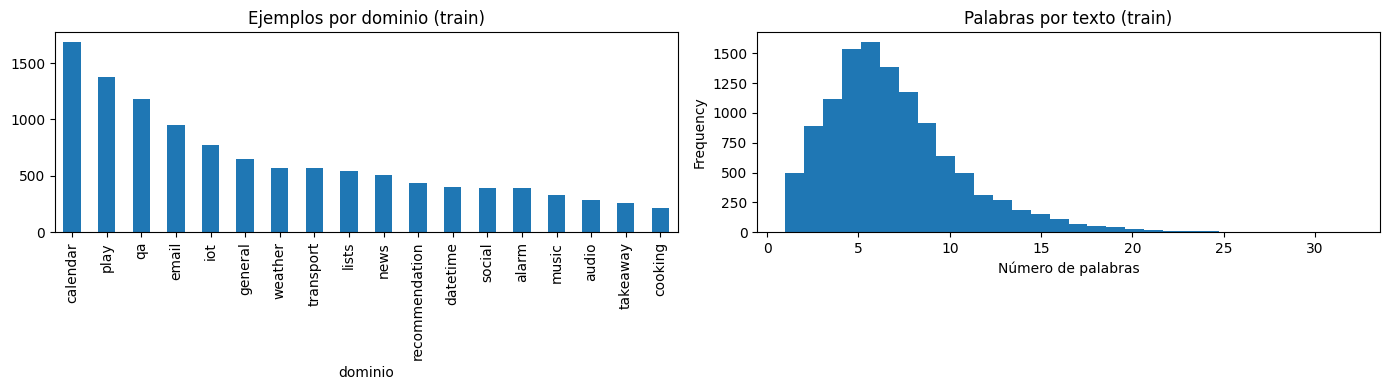

In [1]:
# EnrutaIA - EDA (Día 3)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

ds = load_dataset("mteb/amazon_massive_intent", "es")

# Un solo DataFrame con columna 'split' y columna 'dominio'
partes = []
for split in ["train", "validation", "test"]:
    df_s = ds[split].to_pandas()
    df_s["split"] = split
    partes.append(df_s)
df = pd.concat(partes, ignore_index=True)
df["dominio"] = df["label"].str.split("_").str[0]
df["n_palabras"] = df["text"].str.split().str.len()
df["n_caracteres"] = df["text"].str.len()

# 1) Tamaño y dominios por split
print("Ejemplos por split:\n", df["split"].value_counts().to_string())
print("\nDominios por split:", df.groupby("split")["dominio"].nunique().to_dict())

# 2) Proporción de cada dominio por split (% del split)
prop = (pd.crosstab(df["dominio"], df["split"], normalize="columns") * 100).round(1)
prop = prop[["train", "validation", "test"]].sort_values("train", ascending=False)
print("\n% de cada dominio por split:\n", prop.to_string())

# 3) Longitud de los textos
print("\nPalabras por texto (train):\n", df.loc[df.split == "train", "n_palabras"].describe().round(1).to_string())
print("\nPercentiles 95 y 99 de palabras:",
      np.percentile(df.loc[df.split == "train", "n_palabras"], [95, 99]))

# 4) Duplicados
norm = df["text"].str.lower().str.strip()
print("\nTextos duplicados DENTRO de train:", norm[df.split == "train"].duplicated().sum())
en_train = set(norm[df.split == "train"])
for split in ["validation", "test"]:
    cruce = norm[df.split == split].isin(en_train).sum()
    print(f"Textos de {split} que también están en train: {cruce}")

# Gráficas
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df[df.split == "train"]["dominio"].value_counts().plot.bar(ax=ax[0], title="Ejemplos por dominio (train)")
df[df.split == "train"]["n_palabras"].plot.hist(bins=30, ax=ax[1], title="Palabras por texto (train)")
ax[1].set_xlabel("Número de palabras")
plt.tight_layout(); plt.show()

In [2]:
# EDA - duplicados: ¿misma etiqueta o etiquetas en conflicto?
df["texto_norm"] = norm
conflictos = (df.groupby("texto_norm")["dominio"].nunique() > 1)
print("Textos con MÁS de un dominio distinto (en todo el dataset):", conflictos.sum())
print("\nEjemplos de conflicto:")
print(df[df["texto_norm"].isin(conflictos[conflictos].index[:5])]
      [["split", "text", "dominio"]].sort_values("text").to_string())

Textos con MÁS de un dominio distinto (en todo el dataset): 13

Ejemplos de conflicto:
            split              text   dominio
6641        train             audio      play
12196  validation             audio     audio
4817        train            borrar  calendar
7187        train            borrar     lists
1314        train     buenas noches   general
1376        train     buenas noches     audio
2443        train     buenas noches       iot
4475        train            coches      news
12295  validation            coches   general
1339        train  dime mis alarmas   general
11853  validation  dime mis alarmas     alarm
13560        test  dime mis alarmas     alarm
